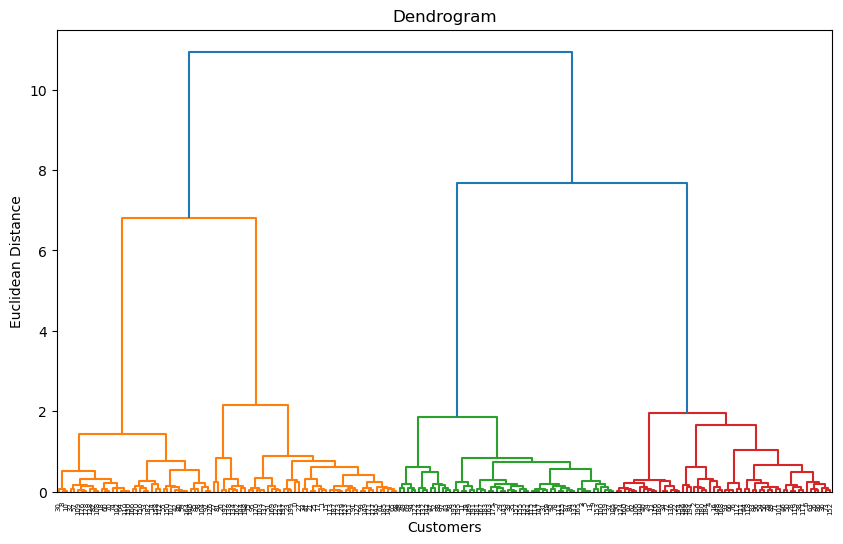

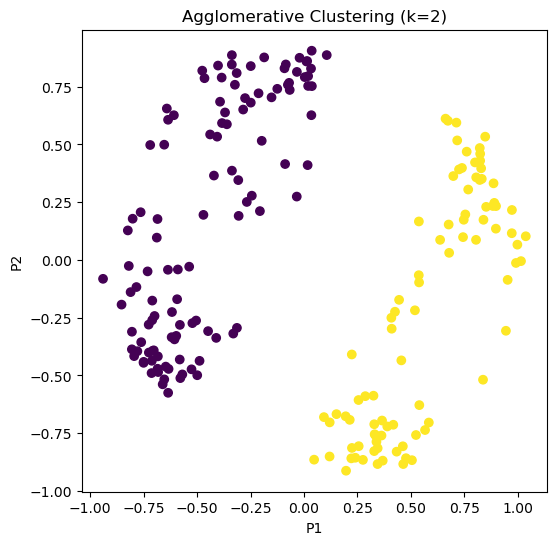

Silhouette Score for k=2: 0.4780


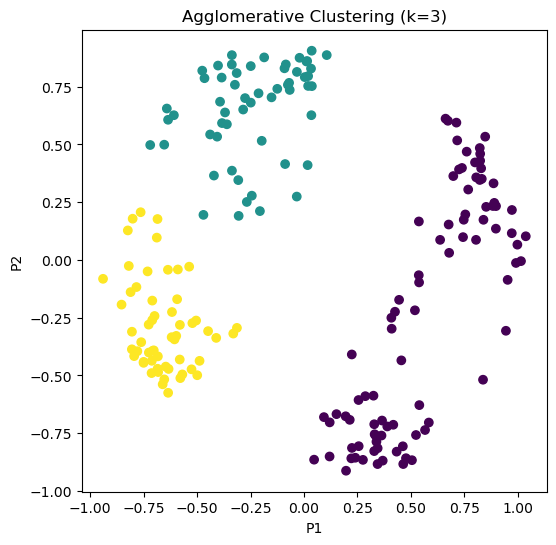

Silhouette Score for k=3: 0.5419


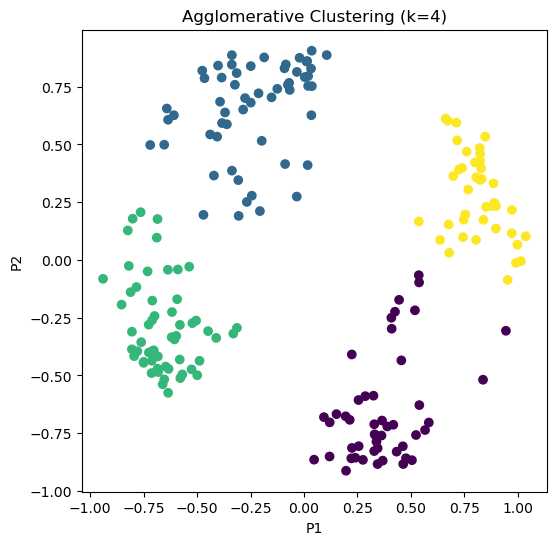

Silhouette Score for k=4: 0.6477


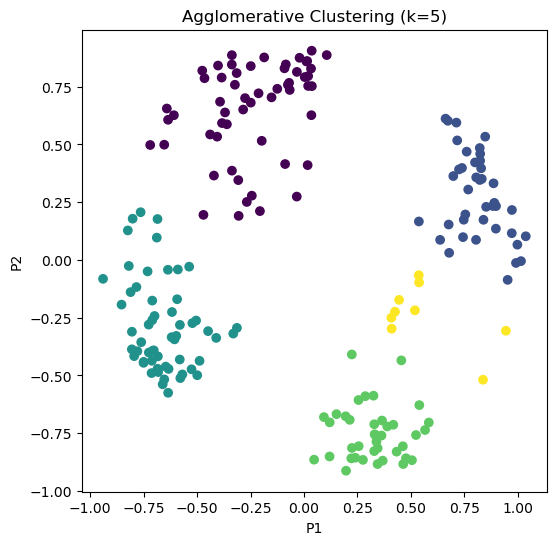

Silhouette Score for k=5: 0.6079


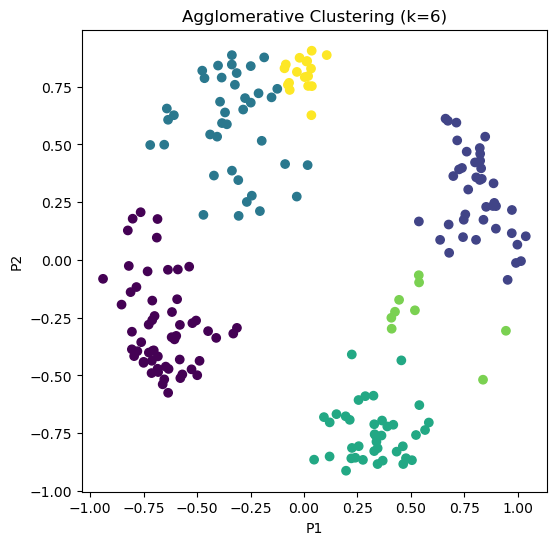

Silhouette Score for k=6: 0.5333


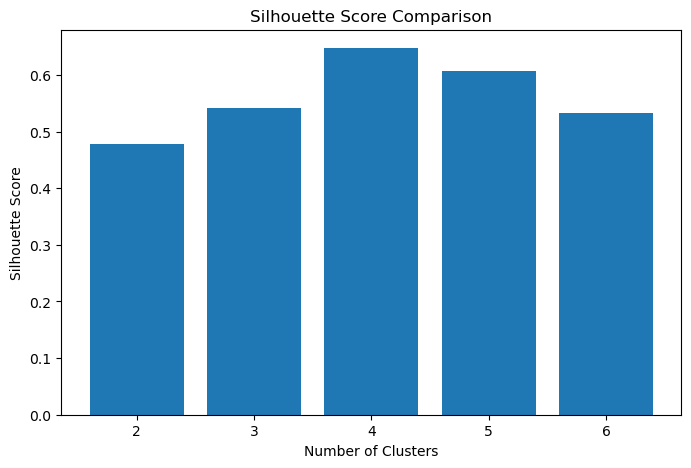


Optimal Number of Clusters = 4

Practical Executed Successfully!


In [3]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

# Step 1: Load Dataset
data = pd.read_csv("P5 Mall_Customers.csv")

# Remove Customer ID
data = data.drop("CustomerID", axis=1)

# Fill missing values
data = data.ffill()

# Convert Gender into numerical values
data = pd.get_dummies(data, columns=['Gender'], drop_first=True, dtype=int)

# Step 2: Preprocessing
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

normalized_data = normalize(scaled_data)

# Step 3: PCA
pca = PCA(n_components=2)
principal = pca.fit_transform(normalized_data)

X = pd.DataFrame(principal, columns=['P1', 'P2'])

# Step 4: Dendrogram
plt.figure(figsize=(10, 6))

linked = linkage(X, method='ward')

dendrogram(linked)

plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")
plt.show()

# Step 5: Agglomerative Clustering
k_values = [2, 3, 4, 5, 6]
silhouette_scores = []

for k in k_values:

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)
    silhouette_scores.append(score)

    plt.figure(figsize=(6, 6))

    plt.scatter(
        X['P1'],
        X['P2'],
        c=labels
    )

    plt.title(f"Agglomerative Clustering (k={k})")
    plt.xlabel("P1")
    plt.ylabel("P2")
    plt.show()

    print(f"Silhouette Score for k={k}: {score:.4f}")

# Step 6: Compare Silhouette Scores
plt.figure(figsize=(8, 5))

plt.bar(k_values, silhouette_scores)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Comparison")

plt.show()

# Find optimal number of clusters
best_k = k_values[np.argmax(silhouette_scores)]

print("\nOptimal Number of Clusters =", best_k)

print("\nPractical Executed Successfully!")

# Practical 5: Agglomerative Hierarchical Clustering
## Oral / Viva Questions and Answers

### 1. What is clustering?
Clustering is an unsupervised machine learning technique used to group similar data points together.

### 2. What is hierarchical clustering?
Hierarchical clustering is a clustering technique that creates a hierarchy of clusters in the form of a tree-like structure.

### 3. What are the two types of hierarchical clustering?
1. Agglomerative clustering (Bottom-up approach).
2. Divisive clustering (Top-down approach).

### 4. What is Agglomerative Clustering?
Agglomerative clustering is a bottom-up clustering algorithm that starts with each data point as a separate cluster and repeatedly merges the closest clusters.

### 5. What is the objective of this practical?
To group similar customers using Agglomerative Hierarchical Clustering and identify suitable clusters.

### 6. Which dataset is used in this practical?
Mall Customers dataset.

### 7. Why is the Mall Customers dataset used?
It contains customer information such as age, gender, annual income, and spending score, which helps in customer segmentation.

### 8. What is customer segmentation?
Customer segmentation is the process of dividing customers into groups based on similar characteristics or behaviour.

### 9. Is Agglomerative Clustering supervised or unsupervised?
It is an unsupervised machine learning algorithm.

### 10. What is the bottom-up approach?
It starts with individual data points and gradually merges them into larger clusters.

### 11. What is the top-down approach?
It starts with one large cluster and repeatedly divides it into smaller clusters.

### 12. What is a dendrogram?
A dendrogram is a tree-like diagram that shows how clusters are merged at different distances.

### 13. Why do we use a dendrogram?
It helps visualize the hierarchical clustering process and choose a suitable number of clusters.

### 14. What is linkage?
Linkage is a method used to calculate the distance between two clusters.

### 15. What are the common linkage methods?
1. Single Linkage
2. Complete Linkage
3. Average Linkage
4. Ward Linkage

### 16. What is Ward Linkage?
Ward Linkage merges clusters that result in the smallest increase in within-cluster variance.

### 17. What is the purpose of StandardScaler?
StandardScaler standardizes features by removing the mean and scaling them to unit variance.

### 18. Why is feature scaling important?
It prevents features with larger numerical ranges from dominating distance calculations.

### 19. What is normalization?
Normalization scales data values to a common range or length, depending on the normalization method.

### 20. What is PCA?
PCA stands for Principal Component Analysis. It is a dimensionality reduction technique used to reduce the number of features while preserving as much variation as possible.

### 21. Why do we use PCA in this practical?
We reduce the data to two dimensions for visualization and clustering.

### 22. What does n_components=2 mean?
It means PCA reduces the dataset to two principal components.

### 23. What is the difference between Standardization and Normalization?
Standardization transforms data based on mean and standard deviation, while normalization scales data according to a chosen norm or range.

### 24. What is Euclidean Distance?
Euclidean distance is the straight-line distance between two points in a multidimensional space.

### 25. What is the purpose of linkage()?
It calculates the hierarchical clustering structure using the selected linkage method.

### 26. What does method='ward' mean?
It uses Ward's method to merge clusters while minimizing the increase in within-cluster variance.

### 27. What is AgglomerativeClustering?
It is a Scikit-learn class used to perform agglomerative hierarchical clustering.

### 28. What does n_clusters=5 mean?
It tells the algorithm to divide the data into five clusters.

### 29. What is fit_predict()?
It fits the clustering model to the data and returns the cluster label assigned to each data point.

### 30. What is a silhouette score?
The silhouette score measures how well each data point fits within its own cluster compared with other clusters.

### 31. What is the range of the silhouette score?
The silhouette score ranges from -1 to +1.

### 32. What does a silhouette score close to +1 indicate?
It indicates that data points are well matched to their own clusters and separated from other clusters.

### 33. What does a silhouette score close to 0 indicate?
It indicates that clusters may overlap or data points lie near cluster boundaries.

### 34. What does a negative silhouette score indicate?
It indicates that some data points may have been assigned to the wrong cluster.

### 35. How do we select the optimal number of clusters?
We compare silhouette scores for different cluster counts. A higher score generally indicates better-separated clusters.

### 36. What is the purpose of matplotlib?
Matplotlib is a Python library used to create graphs and visualizations.

### 37. What does scatter() do?
It creates a scatter plot to visualize data points.

### 38. What does np.argmax() do?
It returns the index of the maximum value in an array.

### 39. Why do we use a bar chart?
To compare silhouette scores for different numbers of clusters.

### 40. What is the advantage of Agglomerative Clustering?
It does not require predefined cluster centers and provides a hierarchical structure that can be visualized using a dendrogram.

### 41. What is the limitation of Agglomerative Clustering?
It can be computationally expensive for large datasets, and early merging decisions cannot normally be reversed.

### 42. Can Agglomerative Clustering handle large datasets?
It can handle small and medium-sized datasets, but it may become expensive for very large datasets.

### 43. What is the difference between K-Means and Agglomerative Clustering?
K-Means is a centroid-based clustering algorithm, while Agglomerative Clustering merges clusters hierarchically.

### 44. What is the final outcome of this practical?
We group customers into clusters using Agglomerative Hierarchical Clustering, visualize the clusters, and compare silhouette scores to select the optimal number of clusters.

---

## Important Code-Based Viva Questions

### 45. Why do we drop CustomerID?
CustomerID is only an identifier and does not provide useful information for customer segmentation.

### 46. What does pd.get_dummies() do?
It converts categorical variables into numerical indicator columns using one-hot encoding.

### 47. What does drop_first=True mean?
It removes the first category to avoid redundant dummy variables.

### 48. Why do we use ffill()?
It fills missing values using the previous valid observation.

### 49. What does fit_transform() do in StandardScaler?
It learns the scaling parameters from the data and transforms the data.

### 50. What does normalize() do?
It scales each sample to unit norm.

### 51. Why do we use PCA after normalization?
To reduce the feature dimensions to two components for visualization and clustering.

### 52. What does silhouette_score(X, labels) calculate?
It calculates the average silhouette coefficient of all data points.

### 53. What does plt.show() do?
It displays the generated graph.

### 54. Why do we use a loop for k_values?
To perform clustering with different numbers of clusters and compare their silhouette scores.

### 55. What does np.argmax(silhouette_scores) return?
It returns the index of the highest silhouette score, which is used to select the corresponding cluster count.

### 56. What is the final result printed by best_k?
It prints the number of clusters that achieved the highest silhouette score among the tested values.